# Laboratorul 09 — Bagging și Random Forest
**Student: Trandafir Florin-Daniel, IASD2601**

Rezolvarea celor șase întrebări din `Ro_09_Bagging_Exercises.ipynb`, folosind
fișierul local `Orange_Telecom_Churn_Data.csv`.

Bagging antrenează arbori pe eșantioane bootstrap (extrase cu înlocuire) și agregă
predicțiile pentru a reduce varianța. Random Forest introduce și selecția aleatoare
a caracteristicilor candidate la fiecare nod. Extra Trees randomizează suplimentar
pragurile de separare; pentru evaluare OOB activăm explicit bootstrap-ul.

Toate experimentele folosesc `random_state=42`. Setul de test nu participă la
alegerea familiei modelului sau a numărului de arbori.

In [13]:
from pathlib import Path
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve,
)

RANDOM_STATE = 42
plt.rcParams.update({'figure.figsize': (9, 5), 'axes.grid': True, 'font.size': 11})
pd.set_option('display.max_columns', 25)
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}')

Python 3.14.2 | pandas 3.0.1 | scikit-learn 1.9.1


## Întrebarea 1 — Import și pregătirea datelor

- Importăm datele și verificăm valorile lipsă și duplicatele.
- Eliminăm `phone_number` (identificator), `area_code` și `state` (coduri geografice,
  fără o ipoteză geografică în acest experiment).
- Codificăm `intl_plan` și `voice_mail_plan`: `no → 0`, `yes → 1`.
  În fișier, coloana se numește `intl_plan`, deși enunțul o menționează ca `int_plan`.
- `churned` este ținta: `False → 0` (rămâne), `True → 1` (renunță).

Arborii nu necesită standardizare. Păstrăm variabilele numerice de consum și cost
pentru comparația cerută; unele sunt puternic corelate, ceea ce contează la interpretarea importanțelor.

In [14]:
data_file = Path('Orange_Telecom_Churn_Data.csv')
if not data_file.is_file():
    raise FileNotFoundError('Rulați notebook-ul din directorul care conține fișierul CSV.')
raw = pd.read_csv(data_file)
print(f'Dimensiune inițială: {raw.shape[0]} rânduri × {raw.shape[1]} coloane')
print(f'Valori lipsă: {raw.isna().sum().sum()} | Rânduri duplicate: {raw.duplicated().sum()}')
display(raw.head())
display(raw.dtypes.rename('Tip inițial').to_frame())

Dimensiune inițială: 5000 rânduri × 21 coloane
Valori lipsă: 0 | Rânduri duplicate: 0


,state,account_length,area_code,phone_number,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,KS,128,415,382-4657,no,yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,371-7191,no,yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,358-1921,no,no,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,375-9999,yes,no,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,330-6626,yes,no,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


,Tip inițial
state,str
account_length,int64
area_code,int64
phone_number,str
intl_plan,str
voice_mail_plan,str
number_vmail_messages,int64
total_day_minutes,float64
total_day_calls,int64
total_day_charge,float64


In [15]:
data = raw.drop(columns=['phone_number', 'area_code', 'state']).copy()
for column in ['intl_plan', 'voice_mail_plan']:
    encoded = data[column].map({'no': 0, 'yes': 1})
    if encoded.isna().any():
        raise ValueError(f'Valori necunoscute în {column}')
    data[column] = encoded.astype('int64')
assert set(data['churned'].unique()) == {False, True}
data['churned'] = data['churned'].astype('int64')
X = data.drop(columns='churned')
y = data['churned']
assert not data.isna().any().any()
assert all(pd.api.types.is_numeric_dtype(dtype) for dtype in X.dtypes)
print(f'După preprocesare: {X.shape[1]} caracteristici; ținta este separată de predictori.')
display(data.dtypes.rename('Tip după codificare').to_frame())
display(data.head())

După preprocesare: 17 caracteristici; ținta este separată de predictori.


,Tip după codificare
account_length,int64
intl_plan,int64
voice_mail_plan,int64
number_vmail_messages,int64
total_day_minutes,float64
total_day_calls,int64
total_day_charge,float64
total_eve_minutes,float64
total_eve_calls,int64
total_eve_charge,float64


,account_length,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,128,0,1,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,0
1,107,0,1,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,0
2,137,0,0,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,0
3,84,1,0,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,0
4,75,1,0,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,0


## Întrebarea 2 — Distribuția țintei și împărțire stratificată

Examinăm distribuția **variabilei țintă** `churned`. Folosim 80% pentru antrenare
și 20% pentru testare. Stratificarea păstrează proporția clasei minoritare în ambele seturi.
Codificările de la întrebarea 1 sunt fixe și nu estimează parametri din setul de test.

,Număr,Procent (%)
churned,,
0,4293,85.86
1,707,14.14


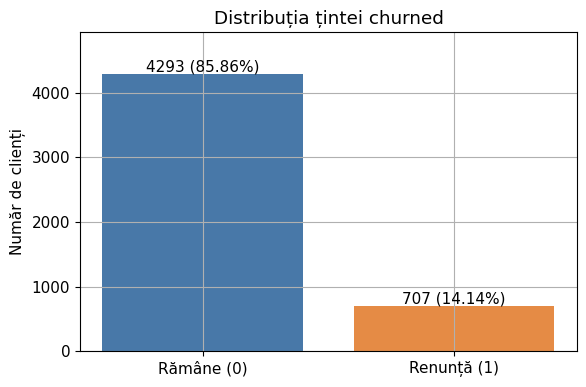

Toate datele             Antrenare              Test            
               Număr Procent (%)     Număr Procent (%) Număr Procent (%)
churned                                                                 
0               4293       85.86      3434       85.85   859        85.9
1                707       14.14       566       14.15   141        14.1

Antrenare: (4000, 17); test: (1000, 17)
Clasa minoritară: 14.14%. Stratificarea este justificată de dezechilibru.


In [16]:
def class_distribution(target):
    counts = target.value_counts().reindex([0, 1], fill_value=0)
    return pd.DataFrame({'Număr': counts, 'Procent (%)': 100 * counts / len(target)})

display(class_distribution(y).rename_axis('churned'))
fig, ax = plt.subplots(figsize=(6, 4))
counts = y.value_counts().reindex([0, 1])
ax.bar(['Rămâne (0)', 'Renunță (1)'], counts, color=['#4878a8', '#e58b45'])
for i, value in enumerate(counts):
    ax.text(i, value + 40, f'{value} ({value / len(y):.2%})', ha='center')
ax.set(title='Distribuția țintei churned', ylabel='Număr de clienți', ylim=(0, counts.max() * 1.15))
plt.tight_layout()
plt.show()

splitter = StratifiedShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y))
X_train, X_test = X.iloc[train_idx].copy(), X.iloc[test_idx].copy()
y_train, y_test = y.iloc[train_idx].copy(), y.iloc[test_idx].copy()
assert set(train_idx).isdisjoint(test_idx)
assert len(train_idx) + len(test_idx) == len(data)
distributions = pd.concat({
    'Toate datele': class_distribution(y),
    'Antrenare': class_distribution(y_train),
    'Test': class_distribution(y_test),
}, axis=1)
display(distributions.round(2).rename_axis('churned'))
print(f'Antrenare: {X_train.shape}; test: {X_test.shape}')
print(f'Clasa minoritară: {y.mean():.2%}. Stratificarea este justificată de dezechilibru.')

## Întrebarea 3 — Random Forest: eroarea OOB și numărul de arbori

Pentru fiecare arbore, observațiile care nu au fost extrase în eșantionul bootstrap
sunt *out-of-bag* (OOB). Scorul OOB agregă pentru fiecare observație numai predicțiile
arborilor care nu au folosit-o la antrenare. Calculăm `eroare OOB = 1 − oob_score_`.

Creștem numărul de arbori cu `warm_start=True` și `set_params`. Păstrăm ceilalți
parametri constanți. La foarte puțini arbori estimarea poate fi instabilă; suprimăm
strict avertismentul specific și afișăm numărul observațiilor fără voturi OOB.

,Model,n_estimators,oob_error,fără_voturi_oob
0,Random Forest,10,0.06475,38
1,Random Forest,20,0.05325,0
2,Random Forest,30,0.04925,0
3,Random Forest,50,0.04650,0
4,Random Forest,75,0.04325,0
5,Random Forest,100,0.04150,0
6,Random Forest,150,0.04125,0
7,Random Forest,200,0.04100,0
8,Random Forest,300,0.04175,0
9,Random Forest,400,0.04075,0


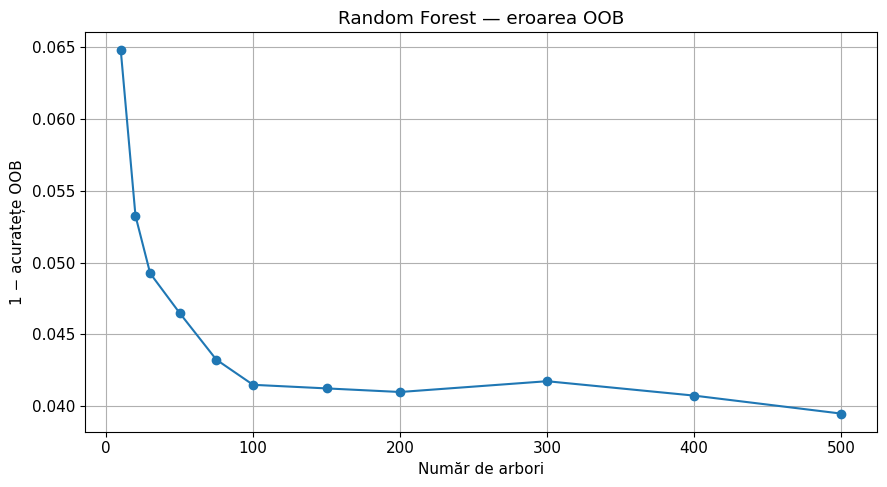

In [17]:
tree_counts = [10, 20, 30, 50, 75, 100, 150, 200, 300, 400, 500]
common_params = dict(
    bootstrap=True, oob_score=True, warm_start=True,
    random_state=RANDOM_STATE, max_features='sqrt', n_jobs=1,
)

def oob_experiment(estimator_class, name):
    model = estimator_class(**common_params)
    rows = []
    for n_trees in tree_counts:
        model.set_params(n_estimators=n_trees)
        with warnings.catch_warnings():
            warnings.filterwarnings(
                'ignore', message='Some inputs do not have OOB scores.*', category=UserWarning
            )
            model.fit(X_train, y_train)
        missing_votes = (model.oob_decision_function_.sum(axis=1) == 0).sum()
        rows.append({
            'Model': name, 'n_estimators': n_trees,
            'oob_error': 1 - model.oob_score_, 'fără_voturi_oob': int(missing_votes),
        })
    return pd.DataFrame(rows)

rf_results = oob_experiment(RandomForestClassifier, 'Random Forest')
display(rf_results.round(5))
fig, ax = plt.subplots()
ax.plot(rf_results['n_estimators'], rf_results['oob_error'], marker='o')
ax.set(title='Random Forest — eroarea OOB', xlabel='Număr de arbori', ylabel='1 − acuratețe OOB')
plt.tight_layout()
plt.show()

## Întrebarea 4 — Extra Trees și comparația cu Random Forest

Repetăm experimentul cu `ExtraTreesClassifier` și `bootstrap=True`, pentru a putea
calcula scorul OOB. Ambele familii folosesc același set de antrenare, aceleași numere
de arbori și `max_features='sqrt'`. Comparația privește configurațiile testate,
nu o superioritate universală a unei familii.

Model,Extra Trees,Random Forest
n_estimators,,
10,0.09375,0.06475
20,0.07350,0.05325
30,0.06800,0.04925
50,0.06250,0.04650
75,0.06100,0.04325
100,0.05725,0.04150
150,0.05800,0.04125
200,0.05675,0.04100
300,0.05775,0.04175


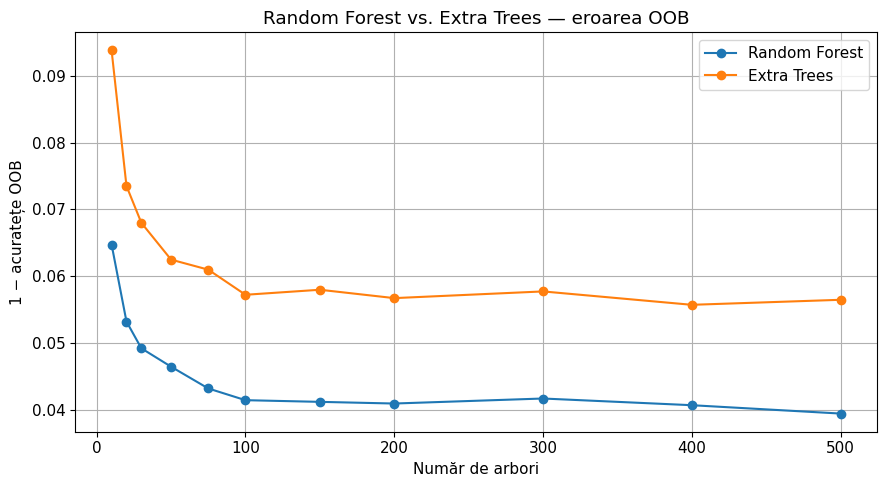

,Model,n_estimators,oob_error,fără_voturi_oob
0,Random Forest,500,0.03950,0
1,Extra Trees,400,0.05575,0


Familia cu eroarea minimă la fiecare număr de arbori (prima coloană în caz de egalitate):


,Număr configurații
Random Forest,11


In [18]:
et_results = oob_experiment(ExtraTreesClassifier, 'Extra Trees')
oob_results = pd.concat([rf_results, et_results], ignore_index=True)
oob_comparison = oob_results.pivot(index='n_estimators', columns='Model', values='oob_error')
display(oob_comparison.round(5))
fig, ax = plt.subplots()
for name, group in oob_results.groupby('Model', sort=False):
    ax.plot(group['n_estimators'], group['oob_error'], marker='o', label=name)
ax.set(title='Random Forest vs. Extra Trees — eroarea OOB',
       xlabel='Număr de arbori', ylabel='1 − acuratețe OOB')
ax.legend()
plt.tight_layout()
plt.show()

# Excludem estimările la care cel puțin o observație nu a primit niciun vot OOB.
eligible = oob_results.loc[oob_results['fără_voturi_oob'].eq(0)]
best_by_family = (eligible.sort_values(['oob_error', 'n_estimators', 'Model'])
                  .drop_duplicates('Model').reset_index(drop=True))
display(best_by_family.round(5))
comparison_wins = oob_comparison.idxmin(axis=1).value_counts()
print('Familia cu eroarea minimă la fiecare număr de arbori (prima coloană în caz de egalitate):')
display(comparison_wins.rename('Număr configurații').to_frame())

## Întrebarea 5 — Selectarea modelului și evaluarea pe test

Alegem configurația cu cea mai mică eroare OOB dintre cele cu voturi complete;
la egalitate preferăm mai puțini arbori. Reantrenăm acea configurație pe întregul
set de antrenare. Pragul de clasificare rămâne cel implicit al clasificatorului,
fără ajustare pe setul de test.

Comparam cu un model de referință care prezice mereu clasa majoritară. Pentru
probabilități calculăm ROC-AUC și Average Precision (AP), rezumat al curbei
precizie–recall, distinct de integrarea trapezoidală a curbei.

In [19]:
best_config = best_by_family.iloc[0]
model_classes = {'Random Forest': RandomForestClassifier, 'Extra Trees': ExtraTreesClassifier}
best_model = model_classes[best_config['Model']](
    n_estimators=int(best_config['n_estimators']), bootstrap=True, oob_score=True,
    max_features='sqrt', random_state=RANDOM_STATE, n_jobs=1,
)
best_model.fit(X_train, y_train)
assert np.isclose(1 - best_model.oob_score_, best_config['oob_error'])
y_pred = best_model.predict(X_test)
positive_column = list(best_model.classes_).index(1)
y_score = best_model.predict_proba(X_test)[:, positive_column]

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)
baseline_score = baseline.predict_proba(X_test)[:, list(baseline.classes_).index(1)]

def evaluate(prediction, probability):
    return {
        'Accuracy': accuracy_score(y_test, prediction),
        'Precision (churn=1)': precision_score(y_test, prediction, zero_division=0),
        'Recall (churn=1)': recall_score(y_test, prediction, zero_division=0),
        'F1 (churn=1)': f1_score(y_test, prediction, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, probability),
        'Average Precision': average_precision_score(y_test, probability),
    }

metrics_table = pd.DataFrame({
    'Clasa majoritară': evaluate(baseline_pred, baseline_score),
    str(best_config['Model']): evaluate(y_pred, y_score),
}).T
print(f"Model selectat: {best_config['Model']}, {int(best_config['n_estimators'])} arbori")
print(f'Eroare OOB la antrenare: {1 - best_model.oob_score_:.4f}')
display(metrics_table.round(4))
print(classification_report(y_test, y_pred, labels=[0, 1],
                            target_names=['Rămâne (0)', 'Renunță (1)'], digits=4, zero_division=0))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
display(pd.DataFrame(cm, index=['Real: rămâne', 'Real: renunță'],
                     columns=['Prezis: rămâne', 'Prezis: renunță']))

Model selectat: Random Forest, 500 arbori
Eroare OOB la antrenare: 0.0395


,Accuracy,Precision (churn=1),Recall (churn=1),F1 (churn=1),ROC-AUC,Average Precision
Clasa majoritară,0.859,0.000,0.000,0.0000,0.5000,0.1410
Random Forest,0.958,0.916,0.773,0.8385,0.9032,0.8708


              precision    recall  f1-score   support

  Rămâne (0)     0.9637    0.9884    0.9759       859
 Renunță (1)     0.9160    0.7730    0.8385       141

    accuracy                         0.9580      1000
   macro avg     0.9398    0.8807    0.9072      1000
weighted avg     0.9570    0.9580    0.9565      1000



,Prezis: rămâne,Prezis: renunță
Real: rămâne,849,10
Real: renunță,32,109


In [20]:
tn, fp, fn, tp = cm.ravel()
selected_metrics = metrics_table.loc[str(best_config['Model'])]
display(Markdown(
    f"**Interpretare:** modelul identifică {tp} din {tp + fn} clienți care renunță "
    f"(recall **{selected_metrics['Recall (churn=1)']:.2%}**) și ratează {fn}. "
    f"Dintre clienții semnalați, {selected_metrics['Precision (churn=1)']:.2%} renunță efectiv; "
    f"există {fp} alarme false. Accuracy este {selected_metrics['Accuracy']:.2%}, "
    f"față de {metrics_table.loc['Clasa majoritară', 'Accuracy']:.2%} pentru referință."
))

**Interpretare:** modelul identifică 109 din 141 clienți care renunță (recall **77.30%**) și ratează 32. Dintre clienții semnalați, 91.60% renunță efectiv; există 10 alarme false. Accuracy este 95.80%, față de 85.90% pentru referință.

**Ce metrică este prioritară?** Dacă scopul este identificarea clienților care vor
renunța pentru o campanie de retenție, recall-ul clasei `1` este prioritar când
ratarea unui client este costisitoare. Precizia controlează intervențiile inutile;
F1 rezumă compromisul dintre ele, iar AP e utilă pentru evaluarea ordonării
clienților într-un set dezechilibrat. Alegerea finală depinde de costurile intervenției
și ale pierderii unui client.

**Ce poate induce în eroare?** Accuracy singură: un model care prezice mereu
„rămâne” are un scor ridicat datorită clasei majoritare și recall zero pentru
clienții care renunță. Aceasta este o referință de clasă majoritară, nu o ghicire
aleatoare. Și eroarea OOB folosită aici se bazează pe accuracy; optimizarea ei nu
garantează recall maxim. Un eventual prag orientat spre recall trebuie ales pe
validare separată sau prin validare încrucișată, nu folosind testul final.

## Întrebarea 6 — Matrice de confuzie, curbe ROC și precizie–recall, importanțe

În matrice, rândurile reprezintă clasele reale, iar coloanele clasele prezise.
Curbele folosesc probabilitatea estimată pentru `churned=1` și toate pragurile posibile.

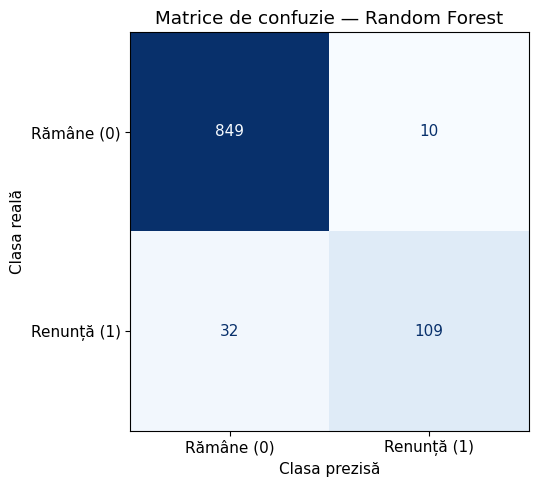

In [21]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=['Rămâne (0)', 'Renunță (1)']).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d'
)
ax.set(title=f"Matrice de confuzie — {best_config['Model']}", xlabel='Clasa prezisă', ylabel='Clasa reală')
ax.grid(False)
plt.tight_layout()
plt.show()

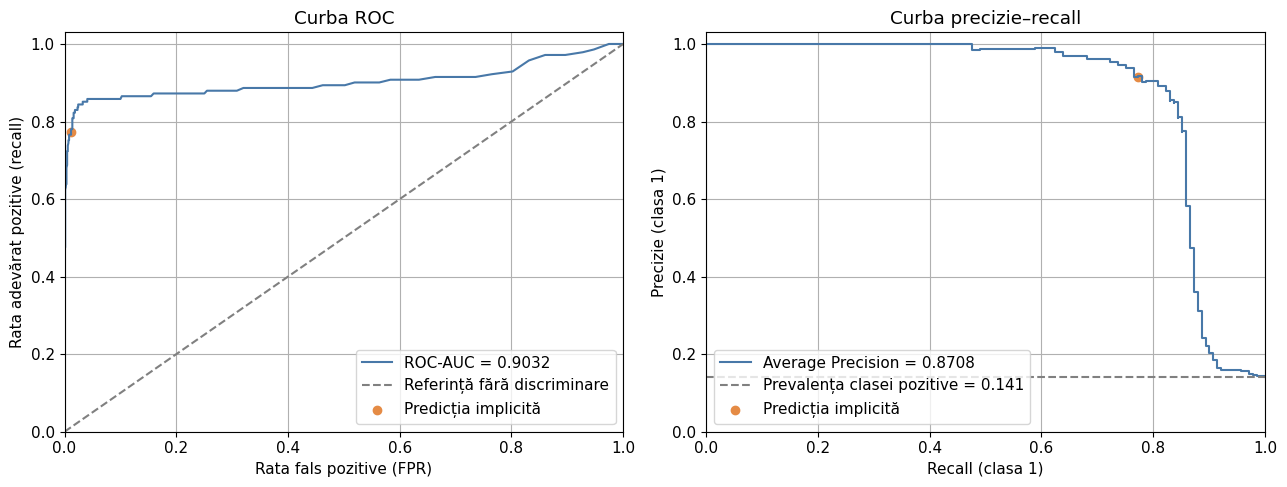

In [22]:
fpr, tpr, roc_thresholds = roc_curve(y_test, y_score)
precision, recall, pr_thresholds = precision_recall_curve(y_test, y_score)
roc_auc = roc_auc_score(y_test, y_score)
ap = average_precision_score(y_test, y_score)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(fpr, tpr, label=f'ROC-AUC = {roc_auc:.4f}', color='#4878a8')
axes[0].plot([0, 1], [0, 1], '--', color='gray', label='Referință fără discriminare')
axes[0].scatter(fp / (fp + tn), tp / (tp + fn), color='#e58b45', label='Predicția implicită')
axes[0].set(title='Curba ROC', xlabel='Rata fals pozitive (FPR)', ylabel='Rata adevărat pozitive (recall)',
            xlim=(0, 1), ylim=(0, 1.03))
axes[0].legend(loc='lower right')
axes[1].step(recall, precision, where='post', label=f'Average Precision = {ap:.4f}', color='#4878a8')
axes[1].axhline(y_test.mean(), linestyle='--', color='gray',
               label=f'Prevalența clasei pozitive = {y_test.mean():.3f}')
axes[1].scatter(recall_score(y_test, y_pred), precision_score(y_test, y_pred),
                color='#e58b45', label='Predicția implicită')
axes[1].set(title='Curba precizie–recall', xlabel='Recall (clasa 1)', ylabel='Precizie (clasa 1)',
            xlim=(0, 1), ylim=(0, 1.03))
axes[1].legend(loc='lower left')
plt.tight_layout()
plt.show()

,Importanță MDI
total_day_minutes,0.1444
total_day_charge,0.1441
number_customer_service_calls,0.1146
intl_plan,0.0837
total_eve_minutes,0.0651
total_eve_charge,0.0633
total_intl_calls,0.0526
total_intl_minutes,0.0439
total_intl_charge,0.0425
total_night_minutes,0.0423


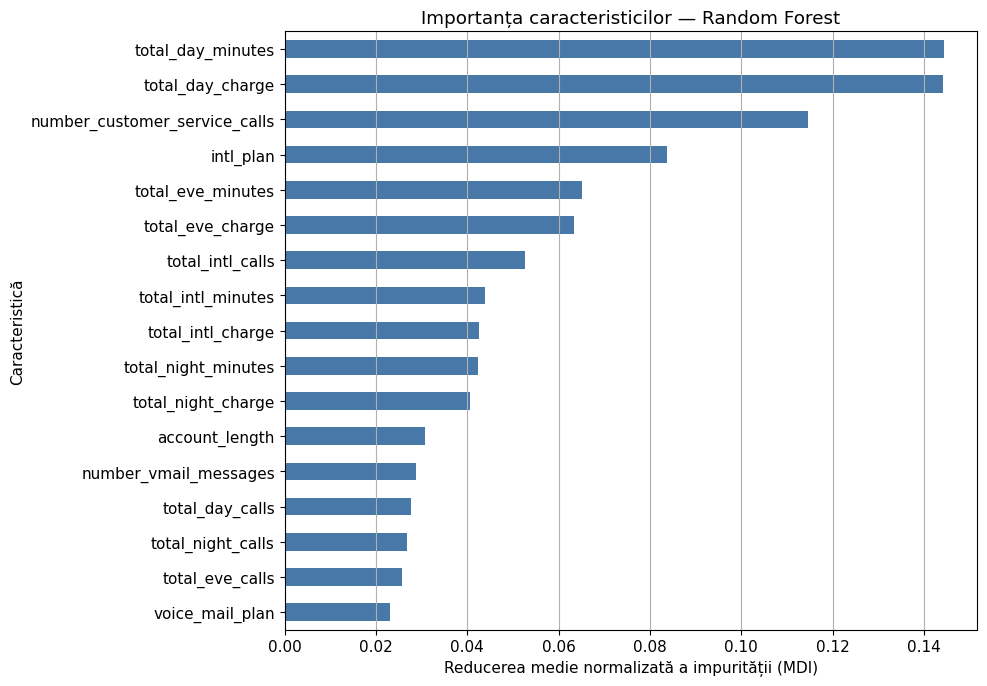

Cele mai importante cinci caracteristici în modelul antrenat sunt: `total_day_minutes`, `total_day_charge`, `number_customer_service_calls`, `intl_plan`, `total_eve_minutes`.

In [23]:
feature_importance = pd.Series(
    best_model.feature_importances_, index=X_train.columns, name='Importanță MDI'
).sort_values(ascending=False)
assert np.isclose(feature_importance.sum(), 1.0)
display(feature_importance.to_frame().round(4))
fig, ax = plt.subplots(figsize=(10, 7))
feature_importance.sort_values().plot.barh(ax=ax, color='#4878a8')
ax.set(title=f"Importanța caracteristicilor — {best_config['Model']}",
       xlabel='Reducerea medie normalizată a impurității (MDI)', ylabel='Caracteristică')
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

top_features = ', '.join(f'`{name}`' for name in feature_importance.head(5).index)
display(Markdown(f'Cele mai importante cinci caracteristici în modelul antrenat sunt: {top_features}.'))

**Interpretarea graficelor.** ROC arată compromisul dintre rata de detecție și
rata alarmelor false. Curba precizie–recall evidențiază mai direct performanța pe
clasa minoritară. Linia de referință PR este prevalența pozitivă din test;
Average Precision trebuie interpretată în raport cu această prevalență.

Importanțele MDI descriu contribuția caracteristicilor la separările arborilor,
nu efecte cauzale. Pot favoriza variabile cu multe valori distincte și pot împărți
importanța între variabile corelate (de exemplu, minute și costuri de convorbire).
O valoare mică nu dovedește că o variabilă este inutilă.

In [24]:
display(Markdown(
    f"**Concluzia experimentului:** dintre configurațiile comparate, "
    f"**{best_config['Model']} cu {int(best_config['n_estimators'])} arbori** a avut "
    f"eroarea OOB minimă ({best_config['oob_error']:.4f}). Pe test, "
    f"F1 pentru churn este **{selected_metrics['F1 (churn=1)']:.4f}**, "
    f"ROC-AUC este **{roc_auc:.4f}**, iar AP este **{ap:.4f}**. "
    "Bagging-ul și randomizarea reduc varianța arborilor; măsurătorile de aici "
    "compară performanța configurațiilor pe această împărțire și nu estimează "
    "direct varianța între mai multe seturi de antrenare."
))

**Concluzia experimentului:** dintre configurațiile comparate, **Random Forest cu 500 arbori** a avut eroarea OOB minimă (0.0395). Pe test, F1 pentru churn este **0.8385**, ROC-AUC este **0.9032**, iar AP este **0.8708**. Bagging-ul și randomizarea reduc varianța arborilor; măsurătorile de aici compară performanța configurațiilor pe această împărțire și nu estimează direct varianța între mai multe seturi de antrenare.